## Q2.0 k-Nearest Neighbours

In [1]:
# Imports necessary libraries & Q1's Dataset.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hashlib
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("data/df.csv")

# Generate seed based on my college ID.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed generated:", seed)
rng = np.random.default_rng(seed)

# Set plotting theme and helper functons.
sns.set_theme(context="paper", style="darkgrid",
              palette="rocket", font="Nimbus Roman")

def plotinfo(title, x, y, userid=username):
    plt.text(0.95, -0.1, userid, ha="right", va="top",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(x, fontsize=12)
    plt.ylabel(y, fontsize=12)
    plt.tight_layout()
    plt.show()

def coordplot(ax, title, x_label, y_label):
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

Seed generated: 1027714457


In [2]:
class PerFeatureTransformer:
    def __init__(self):
        self.scalers_ = {}
        self.encoders_ = {}
        self.numerical_cols_ = []
        self.categorical_cols_ = []

    def fit(self, df: pd.DataFrame, params: dict[str, list[str]]) -> None:
        self.numerical_cols_ = params.get('numerical', [])
        self.categorical_cols_ = params.get('categorical', [])
        for col in self.numerical_cols_:
            scaler = StandardScaler()
            scaler.fit(df[[col]])
            self.scalers_[col] = scaler
        for col in self.categorical_cols_:
            encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
            encoder.fit(df[[col]])
            self.encoders_[col] = encoder
            
    def transform(self, df: pd.DataFrame) -> np.ndarray:
        transformed_parts = []
        for col in self.numerical_cols_:
            scaler = self.scalers_[col]
            transformed_col = scaler.transform(df[[col]])
            transformed_parts.append(transformed_col)
        for col in self.categorical_cols_:
            encoder = self.encoders_[col]
            transformed_col = encoder.transform(df[[col]])
            transformed_parts.append(transformed_col)
        return np.hstack(transformed_parts)

    def fit_transform(self, df: pd.DataFrame, params: dict[str, list[str]]) -> np.ndarray:
        self.fit(df, params)
        return self.transform(df)

In [3]:
class KNNGenderPredictor:
    def __init__(self, student_df: pd.DataFrame, username: str):
        self.df = student_df
        self.username = username
        self.transformer = PerFeatureTransformer()
        self.train_df = None
        self.val_df = None
        self.test_df = None

    def train_val_test_split(self, test_size: float = 0.2, val_size: float = 0.2, 
                seed = seed) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
        train_val_df, self.test_df = train_test_split(self.df, 
                        test_size=test_size, random_state=seed)
        val_size_adjusted = val_size / (1 - test_size)
        self.train_df, self.val_df = train_test_split(train_val_df, 
                    test_size=val_size_adjusted, random_state=seed)
        return self.train_df, self.val_df, self.test_df

    def get_feature_matrix_and_labels(self, df: pd.DataFrame, 
            features: list[str]) -> tuple[np.ndarray, np.ndarray]:
        X = df[features]
        y = df['Gender'].values
        numerical_features = [f for f in features if self.df[f].dtype in ['int64', 'float64']]
        categorical_features = [f for f in features if self.df[f].dtype == 'object']
        params = {
            'numerical': numerical_features,
            'categorical': categorical_features
        }

        if not self.transformer.scalers_:
            X_transformed = self.transformer.fit_transform(X, params)
        else:
            X_transformed = self.transformer.transform(X)
            
        return X_transformed, y

    def get_knn_accuracy_vs_k(self, k_values: list[int], distance: str = "euclidean") -> list[float]:
        features = ['Major', 'Program', 'GPA']
        X_train, y_train = self.get_feature_matrix_and_labels(self.train_df, features)
        X_val, y_val = self.get_feature_matrix_and_labels(self.val_df, features)
        accuracies = []
        for k in k_values:
            knn = KNeighborsClassifier(n_neighbors=k, metric=distance)
            knn.fit(X_train, y_train)
            y_pred = knn.predict(X_val)
            accuracies.append(accuracy_score(y_val, y_pred))
        return accuracies

    def plot_knn_accuracy_vs_k(self, k_values: list[int], distance: str = "euclidean") -> None:
        accuracies = self.get_knn_accuracy_vs_k(k_values, distance)
        plt.figure(figsize=(10, 6))
        plt.plot(k_values, accuracies, marker='o', linestyle='--')
        plotinfo(title=f'k-NN Accuracy vs. k (distance = {distance})',
        x='Number of Neighbors (k)', y='Validation Accuracy', userid=self.username)

    def get_knn_f1_heatmap(self, k_values: list[int], distances: list[str]) -> pd.DataFrame:
        features = ['Major', 'Program', 'GPA']
        X_train, y_train = self.get_feature_matrix_and_labels(self.train_df, features)
        X_val, y_val = self.get_feature_matrix_and_labels(self.val_df, features)
        
        f1_scores = []
        for dist in distances:
            row = {'distance': dist}
            for k in k_values:
                knn = KNeighborsClassifier(n_neighbors=k, metric=dist)
                knn.fit(X_train, y_train)
                y_pred = knn.predict(X_val)
                score = f1_score(y_val, y_pred, average='weighted')
                row[k] = score
            f1_scores.append(row)
            
        return pd.DataFrame(f1_scores).set_index('distance')

    def plot_knn_f1_heatmap(self, f1_scores_df: pd.DataFrame) -> None:
        plt.figure(figsize=(12, 8))
        sns.heatmap(f1_scores_df, annot=True, fmt=".4f", cmap="flare", linewidths=.5)
        plotinfo(title='k-NN F1-Score Heatmap (k vs. Distance Metric)',
        x='Number of Neighbors (k)', y='Distance Metric', userid=self.username)

    def get_knn_f1_single_feature_table(self, k_values: list[int],
        features: list[str], distance: str = "euclidean") -> pd.DataFrame:
        results_dict = {}
        for feature in features:
            single_feature_transformer = PerFeatureTransformer()
            X_train_single = self.train_df[[feature]]
            y_train = self.train_df['Gender'].values
            X_test_single = self.test_df[[feature]]
            y_test = self.test_df['Gender'].values
            params = {
                'numerical': [feature] if self.df[feature].dtype != 'object' else [],
                'categorical': [feature] if self.df[feature].dtype == 'object' else []
            }
            X_train_transformed = single_feature_transformer.fit_transform(X_train_single, params)
            X_test_transformed = single_feature_transformer.transform(X_test_single)
            scores_for_feature = []
            for k in k_values:
                knn = KNeighborsClassifier(n_neighbors=k, metric=distance)
                knn.fit(X_train_transformed, y_train)
                y_pred = knn.predict(X_test_transformed)
                score = f1_score(y_test, y_pred, average='weighted')
                scores_for_feature.append(score)
            results_dict[feature] = scores_for_feature
            
        results_df = pd.DataFrame(results_dict)
        results_df.index = k_values
        results_df.index.name = 'k'
        
        return results_df

It is observed that the **accuracy** of the k-NN classifier generally ***increases with higher values of k*** for all distance metrics, since it considers a larger neighbourhood which leads to a better estimate for classifying the test case.

Hence, *k = 21* is the value which yields the highest accuracy for all distance metrics in our case.

Training set size: 6000
Validation set size: 2000
Test set size: 2000


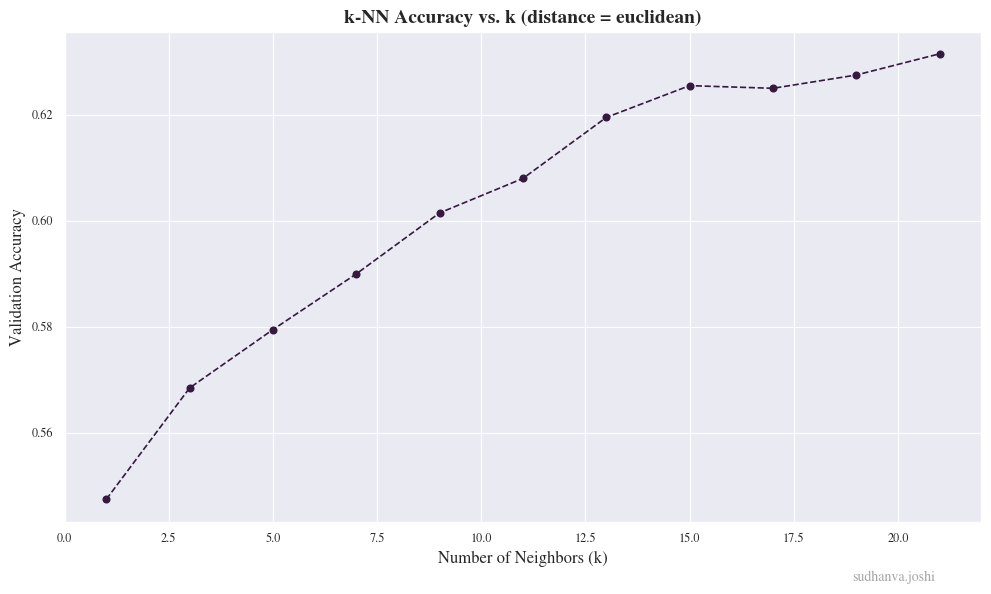

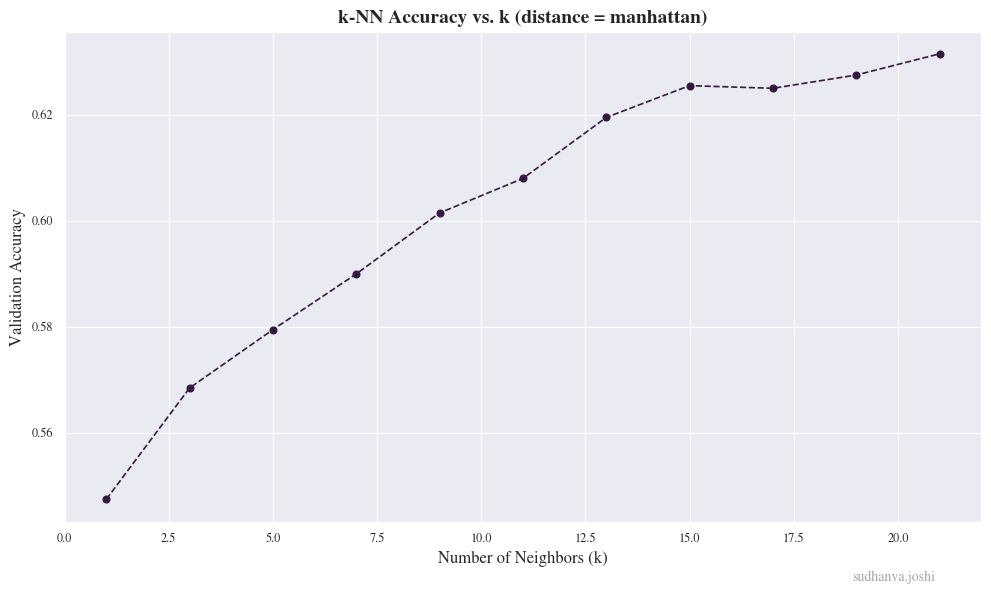

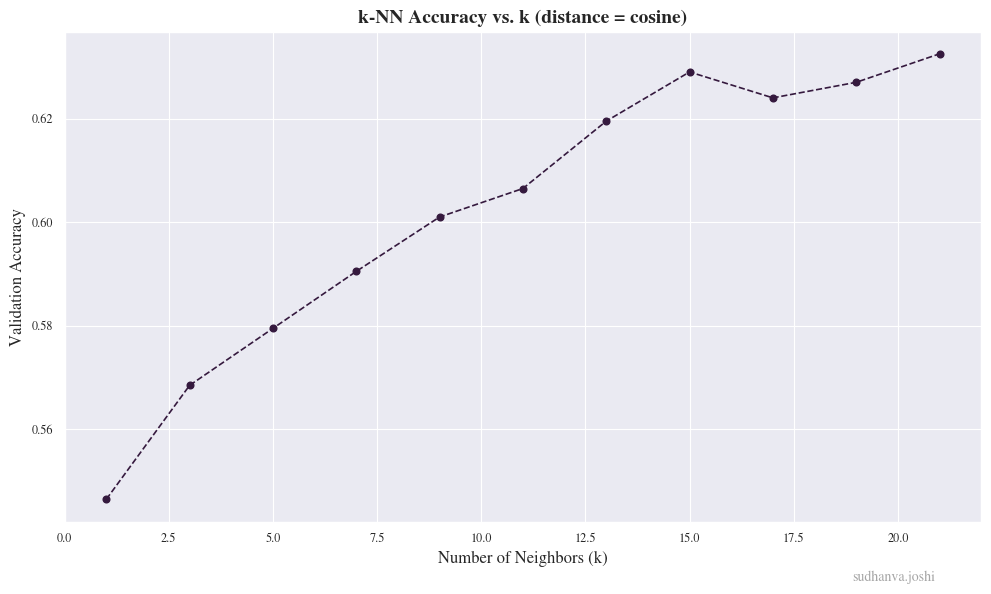

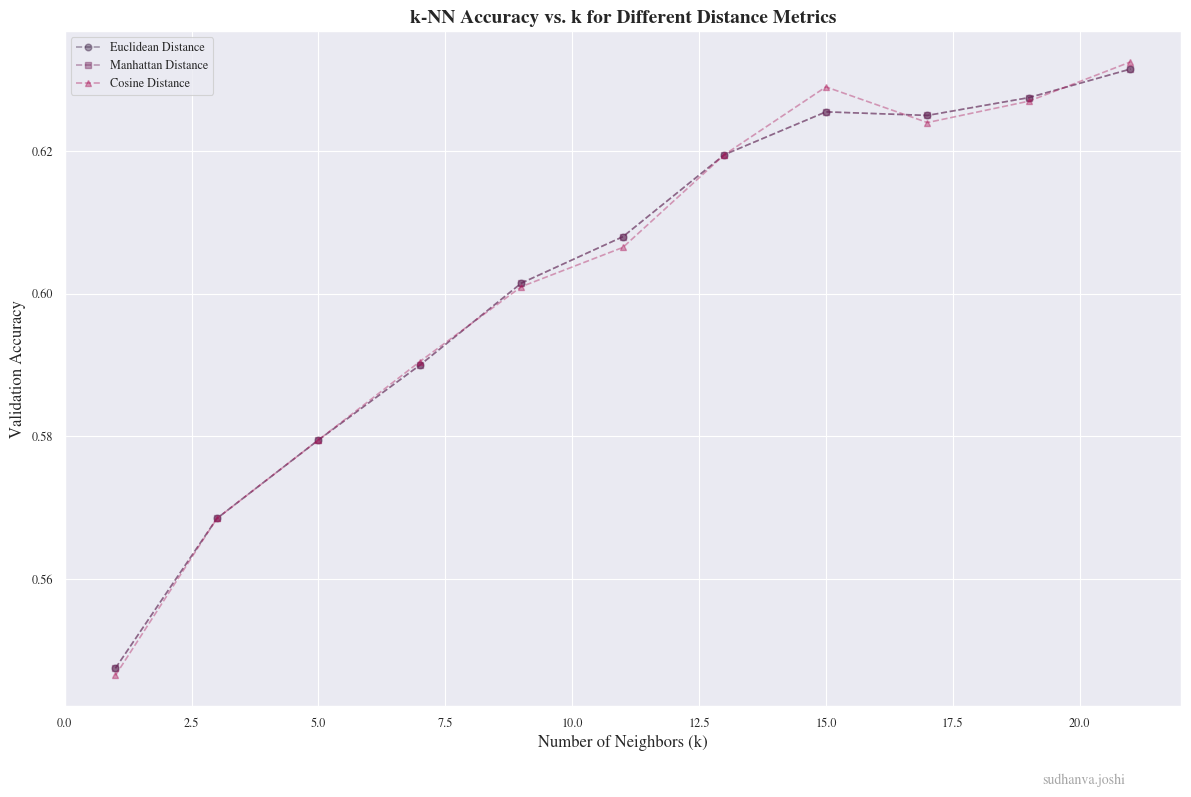

In [4]:
predictor = KNNGenderPredictor(df, username)

train_df, val_df, test_df = predictor.train_val_test_split()
print(f"Training set size: {len(train_df)}")
print(f"Validation set size: {len(val_df)}")
print(f"Test set size: {len(test_df)}")

k_values = list(range(1, 22, 2)) 
distances_to_compare = ["euclidean", "manhattan", "cosine"]

for dist in distances_to_compare:
    predictor.plot_knn_accuracy_vs_k(k_values, distance=dist)
    
markers = ['o', 's', '^'] 
plt.figure(figsize=(12, 8))
for i, dist in enumerate(distances_to_compare):
    accuracies = predictor.get_knn_accuracy_vs_k(k_values, distance=dist)
    plt.plot(k_values, accuracies, marker=markers[i], linestyle='--', 
             alpha=0.4, label=f'{dist.capitalize()} Distance')

plt.legend()
plotinfo(title='k-NN Accuracy vs. k for Different Distance Metrics',
    x='Number of Neighbors (k)', y='Validation Accuracy', userid=predictor.username)

The **F-1 Table Scores** show that both the Euclidean & Manhattan Metrics yield the best (and the same) F-1 Scores during our k-NN iterations. 

This is due to the fact that we are utilizing **binary one-hot encoding** to classify our features, which causes the two metrics to boil down all categorical distances to the ***Hamming Distance***. 

For binary features $x, y \in \{0,1\}$, we have the following distance notion for vector of binary features:

$$
(x - y)^2 = |x - y|
$$

***Note:*** Simply raising k causes models to generally overfit, but since our dataset is arbitrarily generated, this works out in our favour.

The ***Cosine Similarity*** works out to give similar results to the other two metrics since our feature space does not have a strong notion of 'direction' (Our features are independent of each other).

F1 Scores on Validation Set
distance  euclidean  manhattan    cosine
1          0.550327   0.550327  0.549463
3          0.554393   0.554393  0.554182
5          0.549162   0.549162  0.549162
7          0.549087   0.549087  0.549805
9          0.553264   0.553264  0.552516
11         0.551931   0.551931  0.550896
13         0.558865   0.558865  0.557490
15         0.553098   0.553098  0.556959
17         0.545188   0.545188  0.543988
19         0.541164   0.541164  0.540254
21         0.534567   0.534567  0.534495


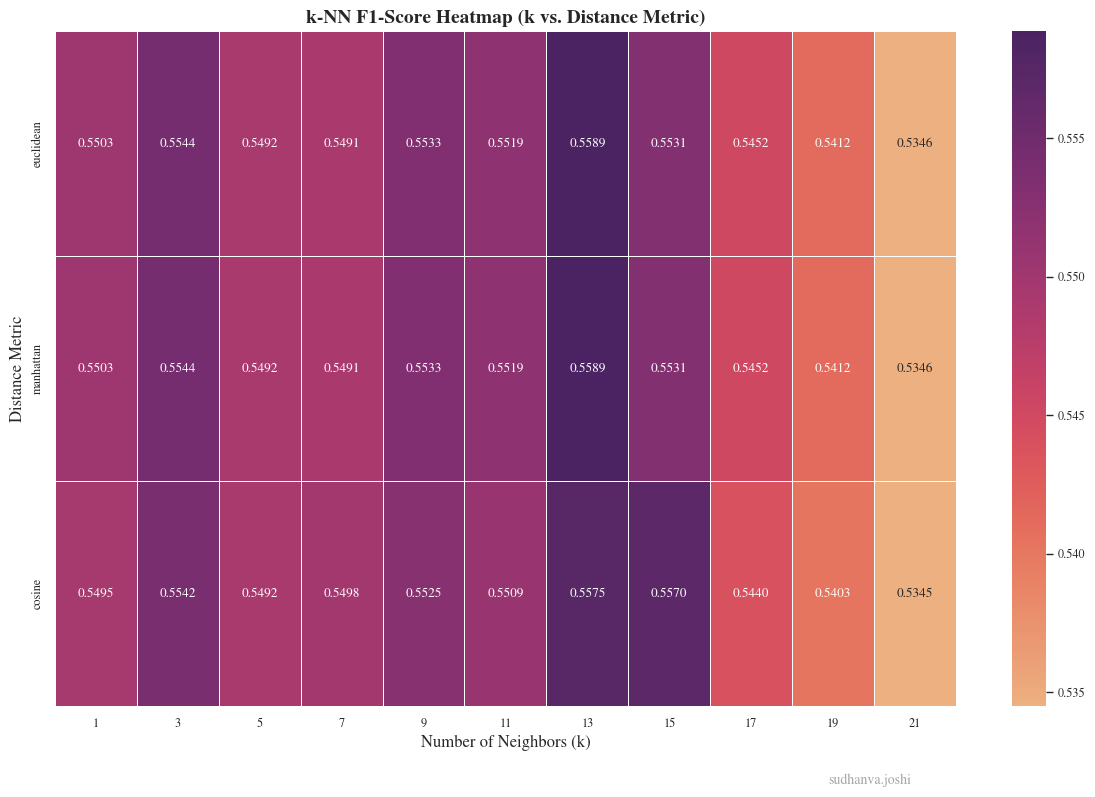

In [5]:
distances = ["euclidean", "manhattan", "cosine"]
f1_scores_df = predictor.get_knn_f1_heatmap(k_values, distances)
print("F1 Scores on Validation Set")
print(f1_scores_df.transpose())
predictor.plot_knn_f1_heatmap(f1_scores_df)

The best ***F-1 Score*** on single-feature testing is offered by **Program**. However, it is approximately equal in performance to the full-feature prediction tests. 

This is due to the fact that all features are **relatively indepedent** of each other, which means that no feature is directly a good predictor of gender. Hence, the optimal classification strategy is to go with a majority prediction *(Male)* in this case.

In [6]:
features_to_test = ['GPA', 'Major', 'Program']

print("Single Feature F1 Scores on Test Set, Euclidean Metric")
f1_table_euclidean = predictor.get_knn_f1_single_feature_table(k_values, 
                                features_to_test, distance="euclidean")
print(f1_table_euclidean)

print("Single Feature F1 Scores on Test Set, Manhattan Metric")
f1_table_manhattan = predictor.get_knn_f1_single_feature_table(k_values, 
                                features_to_test, distance="manhattan")
print(f1_table_manhattan)

print("Single Feature F1 Scores on Test Set, Cosine Metric")
f1_table_cosine = predictor.get_knn_f1_single_feature_table(k_values, 
                                features_to_test, distance="cosine")
print(f1_table_cosine)

Single Feature F1 Scores on Test Set, Euclidean Metric
         GPA     Major   Program
k                               
1   0.527800  0.534068  0.540997
3   0.544203  0.508329  0.540997
5   0.544130  0.544568  0.522508
7   0.541814  0.508329  0.522508
9   0.550352  0.508329  0.522508
11  0.548984  0.508329  0.522508
13  0.545254  0.508329  0.522508
15  0.546194  0.508329  0.522508
17  0.543549  0.508329  0.522508
19  0.541222  0.508329  0.522508
21  0.540638  0.508329  0.522508
Single Feature F1 Scores on Test Set, Manhattan Metric
         GPA     Major   Program
k                               
1   0.527800  0.534068  0.540997
3   0.544203  0.508329  0.540997
5   0.544130  0.544568  0.522508
7   0.541814  0.508329  0.522508
9   0.550352  0.508329  0.522508
11  0.548984  0.508329  0.522508
13  0.545254  0.508329  0.522508
15  0.546194  0.508329  0.522508
17  0.543549  0.508329  0.522508
19  0.541222  0.508329  0.522508
21  0.540638  0.508329  0.522508
Single Feature F1 Scores on Test